# Incertezze e covarianze - Prova 3
## Fase Preliminare
In questa fase preliminare settiamo tutto il necessario: parametri del fit con la loro covarianza, calibrazioni scelte da noi e funzioni per passare da $z = (\alpha, \delta, k, s_x)^T$ a $g = (a, d, q)^T$:
$$ a = \frac{\alpha}{k s_x} \qquad d = \frac{\delta}{k s_x} \qquad q = \frac{d}{a} = \frac{\delta}{\alpha} $$
Per le calibrazioni scegliamo $k = 4.83$ mm$^{-2}$ con incertezza relativa dell'1.5 % (ad esempio $k = \pi/(\lambda L)$ con $\lambda = 650$ nm e $L = 1$ m) e $s_x = 1.000$ con incertezza relativa dell'1 %.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Stile comune del corso.
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
ARANCIONE = "#FFA500"
plt.rcParams.update(
    {
        "figure.figsize": (8.2, 4.6),
        "figure.dpi": 120,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.labelsize": 11,
        "axes.titlesize": 12,
        "font.size": 11,
        "legend.frameon": False,
    }
)

# fit parameters (mm^-1)
alpha, u_alpha = 0.910, 0.018
delta, u_delta = 5.180, 0.045
rho = -0.65

# calibrations chosen by us, independent
k, u_k = 4.83, 0.015 * 4.83     # mm^-2
sx, u_sx = 1.000, 0.010         # dimensionless

z0 = np.array([alpha, delta, k, sx])

def g(z):
    a = z[..., 0] / (z[..., 2] * z[..., 3])
    d = z[..., 1] / (z[..., 2] * z[..., 3])
    q = z[..., 1] / z[..., 0]
    return np.stack([a, d, q], axis=-1)

def jacobian(z):
    alpha, delta, k, sx = z
    return np.array([[1/(k*sx), 0, -alpha/(k**2*sx), -alpha/(k*sx**2)],
                     [0, 1/(k*sx), -delta/(k**2*sx), -delta/(k*sx**2)],
                     [-delta/alpha**2, 1/alpha, 0, 0]])

def covarianza(rho=rho, fit=1, uk=u_k, usx=u_sx):
    # block diagonal: fit block (alpha, delta), then k and sx
    C = np.zeros((4, 4))
    C[:2, :2] = fit * np.array([[u_alpha**2, rho * u_alpha * u_delta],
                                [rho * u_alpha * u_delta, u_delta**2]])
    C[2, 2] = uk**2
    C[3, 3] = usx**2
    return C

def monte_carlo(C, M=100_000):
    rng = np.random.default_rng(20261003)
    return rng.multivariate_normal(z0, C, size=M)

## Attività 1
Costruiamo la matrice di covarianza $4 \times 4$ di $z$, a blocchi, supponendo $k$ e $s_x$ indipendenti tra loro e dal fit:
$$ C_z = \begin{pmatrix} C_{\alpha\delta} & 0 \\ 0 & \mathrm{diag}(u^2(k), u^2(s_x)) \end{pmatrix} $$
Verifichiamo che sia simmetrica, con diagonale positiva e autovalori non negativi. Calcoliamo infine la matrice di correlazione e la rappresentiamo con una mappa di colore.

[[ 0.000324  -0.0005265  0.         0.       ]
 [-0.0005265  0.002025   0.         0.       ]
 [ 0.         0.         0.005249   0.       ]
 [ 0.         0.         0.         0.0001   ]]
C_z è simmetrica: True
La diagonale è positiva: True
Autovalori: [0.0001     0.00017422 0.00217478 0.005249  ]
Autovalori non negativi: True
Autovalori di [[1, 2], [2, 1]]: [-1.  3.]
rho(alpha, delta) = -0.65


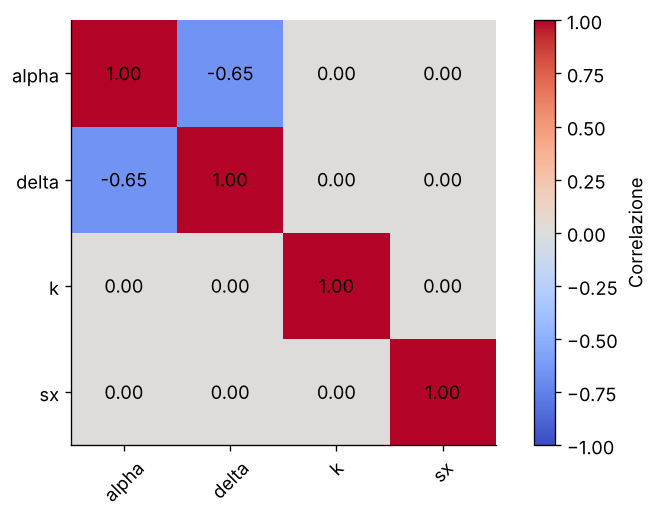

In [2]:
C_z = covarianza()
print(C_z)

autovalori = np.linalg.eigvalsh(C_z)
print(f"C_z è simmetrica: {np.allclose(C_z, C_z.T)}")
print(f"La diagonale è positiva: {np.all(np.diag(C_z) > 0)}")
print(f"Autovalori: {autovalori}")
print(f"Autovalori non negativi: {np.all(autovalori >= -1e-12 * autovalori.max())}")

# a symmetric matrix with positive diagonal that is not a covariance
print(f"Autovalori di [[1, 2], [2, 1]]: {np.linalg.eigvalsh([[1, 2], [2, 1]])}")

# correlation matrix
corr_z = C_z / np.outer(np.sqrt(np.diag(C_z)), np.sqrt(np.diag(C_z)))
print(f"rho(alpha, delta) = {corr_z[0, 1]:.2f}")

plt.imshow(corr_z, cmap="coolwarm", vmin=-1, vmax=1)
labels = ["alpha", "delta", "k", "sx"]
plt.xticks(range(len(labels)), labels, rotation=45)
plt.yticks(range(len(labels)), labels)
plt.colorbar(label="Correlazione")
for i in range(len(corr_z)):
    for j in range(len(corr_z)):
        plt.text(j, i, f"{corr_z[i, j]:.2f}",
                 ha="center", va="center")

plt.show()

Simmetria e diagonale positiva non bastano: una covarianza deve essere semidefinita positiva (autovalori $\geq 0$), altrimenti esisterebbero combinazioni lineari delle variabili con varianza negativa. La matrice $\begin{pmatrix} 1 & 2 \\ 2 & 1 \end{pmatrix}$ è simmetrica con diagonale positiva ma ha un autovalore negativo.

## Attività 2
Propaghiamo linearmente le incertezze a $g$:
$$ C_g = J C_z J^T $$
Calcoliamo valori centrali, incertezze marginali e matrice di correlazione di $a$, $d$, $q$. Per $q$ verifichiamo anche la formula del rapporto:
$$ \left(\frac{u(q)}{q}\right)^2 = \left(\frac{u(\delta)}{\delta}\right)^2 + \left(\frac{u(\alpha)}{\alpha}\right)^2 - 2 \frac{cov(\alpha, \delta)}{\alpha \delta} $$

In [3]:
J = jacobian(z0)
g0 = g(z0)
C_g = J @ C_z @ J.T
u_lin = np.sqrt(np.diag(C_g))
corr_g = C_g / np.outer(u_lin, u_lin)

print(f"a = {g0[0]:.4f} ± {u_lin[0]:.4f} mm")
print(f"d = {g0[1]:.3f} ± {u_lin[1]:.3f} mm")
print(f"q = {g0[2]:.2f} ± {u_lin[2]:.2f}")
print(f"Matrice di correlazione di (a, d, q):\n{corr_g}")

# check on q
rel_q = np.sqrt((u_delta / delta)**2 + (u_alpha / alpha)**2 - 2 * C_z[0, 1] / (alpha * delta))
print(f"u(q)/q = {u_lin[2] / g0[2]:.5f} (Jacobiano), {rel_q:.5f} (formula)")

a = 0.1884 ± 0.0050 mm


d = 1.072 ± 0.021 mm
q = 5.69 ± 0.15
Matrice di correlazione di (a, d, q):
[[ 1.          0.39827754 -0.71537021]
 [ 0.39827754  1.          0.356019  ]
 [-0.71537021  0.356019    1.        ]]
u(q)/q = 0.02627 (Jacobiano), 0.02627 (formula)


## Attività 3
Generiamo $10^5$ campioni gaussiani correlati di $z$, verifichiamo che siano fisicamente ammissibili (tutti positivi) e calcoliamo $a$, $d$, $q$ per ogni campione. Per ogni grandezza riportiamo media, deviazione standard (`ddof=1`), mediana e percentili 16 e 84, e le confrontiamo con la propagazione lineare. Infine mostriamo l'istogramma di $q$ e lo scatter dei campioni nel piano $(\alpha, \delta)$.

Campioni fisicamente ammissibili (tutti > 0): True
   nominale  u lineare  media MC    std MC  mediana MC       p16       p84
a  0.188406   0.005042  0.188474  0.005040    0.188406  0.183458  0.193480
d  1.072464   0.021462  1.072847  0.021501    1.072559  1.051526  1.094253
q  5.692308   0.149537  5.695146  0.149812    5.692755  5.546329  5.843754


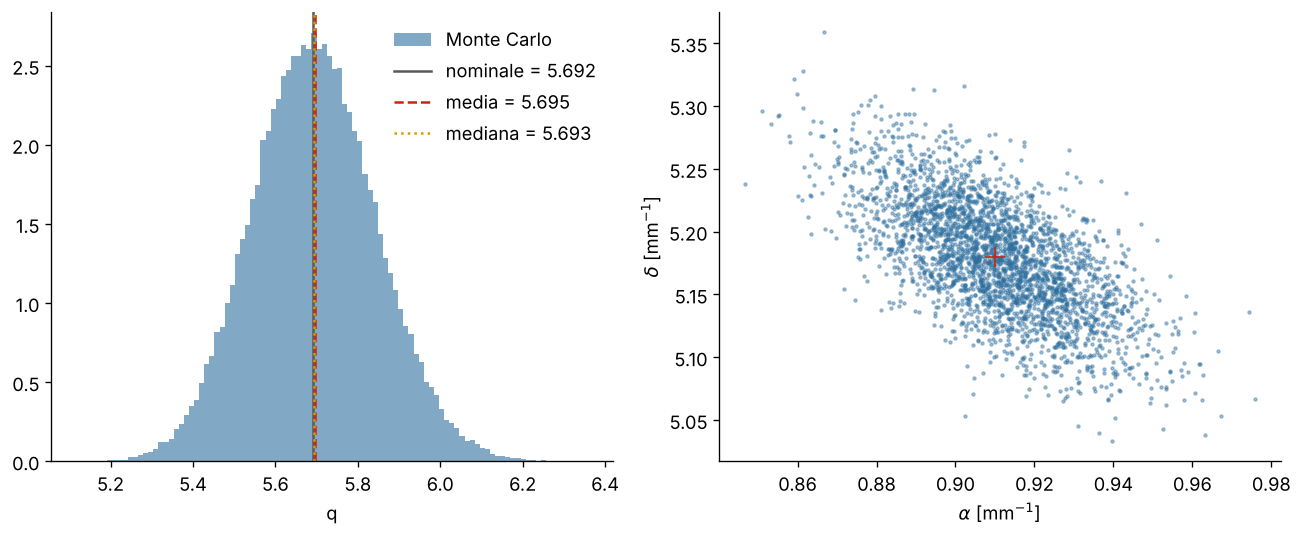

In [4]:
z_mc = monte_carlo(C_z)
print(f"Campioni fisicamente ammissibili (tutti > 0): {np.all(z_mc > 0)}")
g_mc = g(z_mc)

tab = pd.DataFrame({
    "nominale": g0,
    "u lineare": u_lin,
    "media MC": g_mc.mean(axis=0),
    "std MC": g_mc.std(axis=0, ddof=1),
    "mediana MC": np.median(g_mc, axis=0),
    "p16": np.percentile(g_mc, 16, axis=0),
    "p84": np.percentile(g_mc, 84, axis=0),
}, index=["a", "d", "q"])
print(tab)

q_mc = g_mc[:, 2]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
ax[0].hist(q_mc, bins=100, density=True, color=AZZURRO, alpha=0.6, label="Monte Carlo")
ax[0].axvline(g0[2], color=GRIGIO, label=f"nominale = {g0[2]:.3f}")
ax[0].axvline(q_mc.mean(), color=ROSSO, linestyle="--", label=f"media = {q_mc.mean():.3f}")
ax[0].axvline(np.median(q_mc), color=ORO, linestyle=":", label=f"mediana = {np.median(q_mc):.3f}")
ax[0].set_xlabel("q")
ax[0].legend()
ax[1].scatter(z_mc[:3000, 0], z_mc[:3000, 1], s=3, alpha=0.4, color=AZZURRO)
ax[1].plot(alpha, delta, "+", color=ROSSO, markersize=12)
ax[1].set_xlabel(r"$\alpha$ [mm$^{-1}$]")
ax[1].set_ylabel(r"$\delta$ [mm$^{-1}$]")
plt.tight_layout()
plt.show()

I due metodi sono in accordo. *Centro*: media e mediana MC coincidono con il valore nominale entro circa il 2 % di $\sigma$ (bias di secondo ordine dovuto alla non linearità). *Dispersione*: il rapporto tra deviazione standard MC e incertezza lineare è 1 entro lo 0.2 %, cioè entro il rumore del Monte Carlo. *Simmetria*: $p_{84}$ - mediana e mediana - $p_{16}$ coincidono entro il 3 %, le distribuzioni sono praticamente gaussiane.

## Attività 4
Ripetiamo il calcolo analitico e Monte Carlo ponendo a zero soltanto la covarianza tra $\alpha$ e $\delta$ ($\rho = 0$), e confrontiamo $u(a)$, $u(d)$ e $u(q)$ con i valori nominali.

   u lin (rho=-0.65)  u lin (rho=0)  variazione lin [%]  u MC (rho=-0.65)  \
a           0.005042       0.005042            0.000000          0.005040   
d           0.021462       0.021462            0.000000          0.021501   
q           0.149537       0.122976          -17.762304          0.149812   

   u MC (rho=0)  variazione MC [%]  
a      0.005045           0.103384  
d      0.021501           0.002059  
q      0.123191         -17.769636  
Matrice di correlazione di (a, d, q) con rho=0:
[[ 1.          0.60682677 -0.67670123]
 [ 0.60682677  1.          0.17456234]
 [-0.67670123  0.17456234  1.        ]]


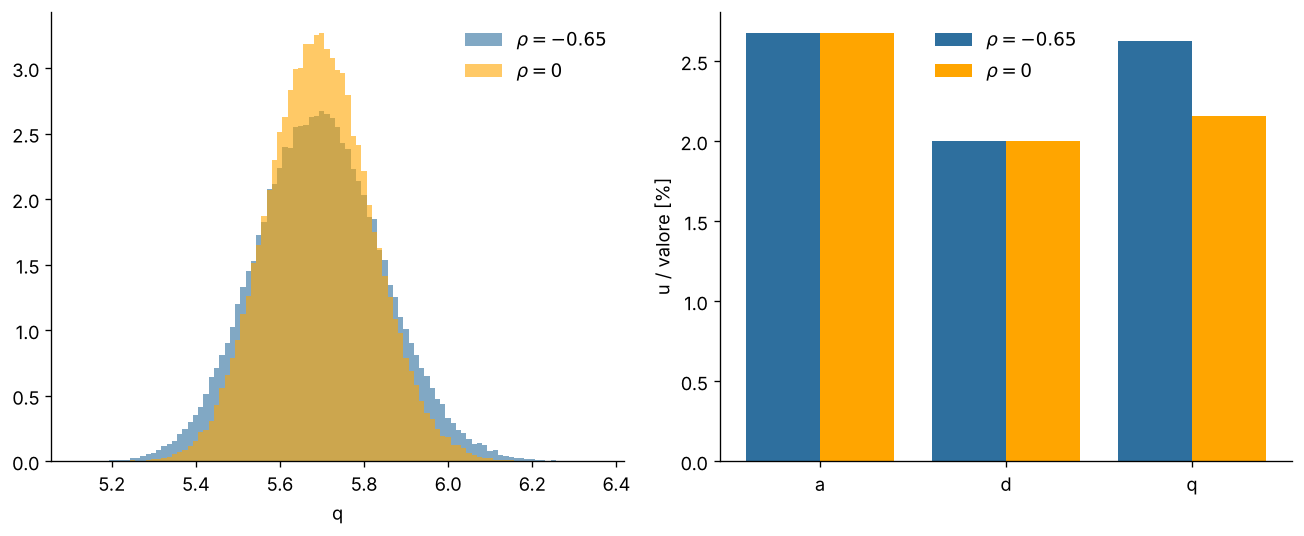

In [5]:
C_z0 = covarianza(rho=0)
C_g0 = J @ C_z0 @ J.T
u_lin0 = np.sqrt(np.diag(C_g0))
corr_g0 = C_g0 / np.outer(u_lin0, u_lin0)
g_mc0 = g(monte_carlo(C_z0))
u_mc = g_mc.std(axis=0, ddof=1)
u_mc0 = g_mc0.std(axis=0, ddof=1)

tab4 = pd.DataFrame({
    "u lin (rho=-0.65)": u_lin,
    "u lin (rho=0)": u_lin0,
    "variazione lin [%]": 100 * (u_lin0 / u_lin - 1),
    "u MC (rho=-0.65)": u_mc,
    "u MC (rho=0)": u_mc0,
    "variazione MC [%]": 100 * (u_mc0 / u_mc - 1),
}, index=["a", "d", "q"])
print(tab4)
print(f"Matrice di correlazione di (a, d, q) con rho=0:\n{corr_g0}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
bins = np.linspace(q_mc.min(), q_mc.max(), 100)
ax[0].hist(g_mc[:, 2], bins=bins, density=True, color=AZZURRO, alpha=0.6, label=r"$\rho = -0.65$")
ax[0].hist(g_mc0[:, 2], bins=bins, density=True, color=ARANCIONE, alpha=0.6, label=r"$\rho = 0$")
ax[0].set_xlabel("q")
ax[0].legend()
x = np.arange(3)
ax[1].bar(x - 0.2, 100 * u_lin / g0, 0.4, color=AZZURRO, label=r"$\rho = -0.65$")
ax[1].bar(x + 0.2, 100 * u_lin0 / g0, 0.4, color=ARANCIONE, label=r"$\rho = 0$")
ax[1].set_xticks(x, ["a", "d", "q"])
ax[1].set_ylabel("u / valore [%]")
ax[1].legend()
plt.tight_layout()
plt.show()

1. Cambia solo $u(q)$ (circa -18 %: da 2.6 % a 2.2 % del valore) e cambiano le correlazioni in $C_g$. Valori centrali, $u(a)$ e $u(d)$ restano uguali.
2. $u(a)$ e $u(d)$ restano uguali perché nelle righe di $J$ per $a$ e $d$ compare una sola tra $\alpha$ e $\delta$: $cov(\alpha, \delta)$ non entra mai nelle loro varianze. Serve solo a $q$, che le usa entrambe.
3. Per un rapporto $\rho < 0$ fa sommare gli errori, quindi ignorarla sottostima $u(q)$ (qui). Con $\rho > 0$ sarebbe il contrario, e per un prodotto o una somma l'effetto si inverte: dipende dal segno di $\rho$ e da come le grandezze si combinano.

## Attività 5
Studiamo separatamente tre gruppi di sorgenti: il blocco correlato del fit $(\alpha, \delta)$, trattato congiuntamente, la calibrazione $k$ e la calibrazione dell'asse $s_x$. Lasciamo fluttuare un gruppo alla volta, tenendo di $C_z$ solo il suo blocco (gli altri input restano ai valori nominali), e calcoliamo la varianza $u_j^2(g)$ prodotta su $a$, $d$, $q$ con Monte Carlo e analiticamente. Definiamo
$$ F_j(g) = \frac{u_j^2(g)}{\sum_l u_l^2(g)} $$

F_j [%] lineare:
     fit     k    sx
a   54.6  31.4  14.0
d   18.8  56.2  25.0
q  100.0   0.0   0.0
F_j [%] Monte Carlo:
     fit     k    sx
a   54.7  31.4  13.9
d   18.8  56.2  25.0
q  100.0   0.0   0.0


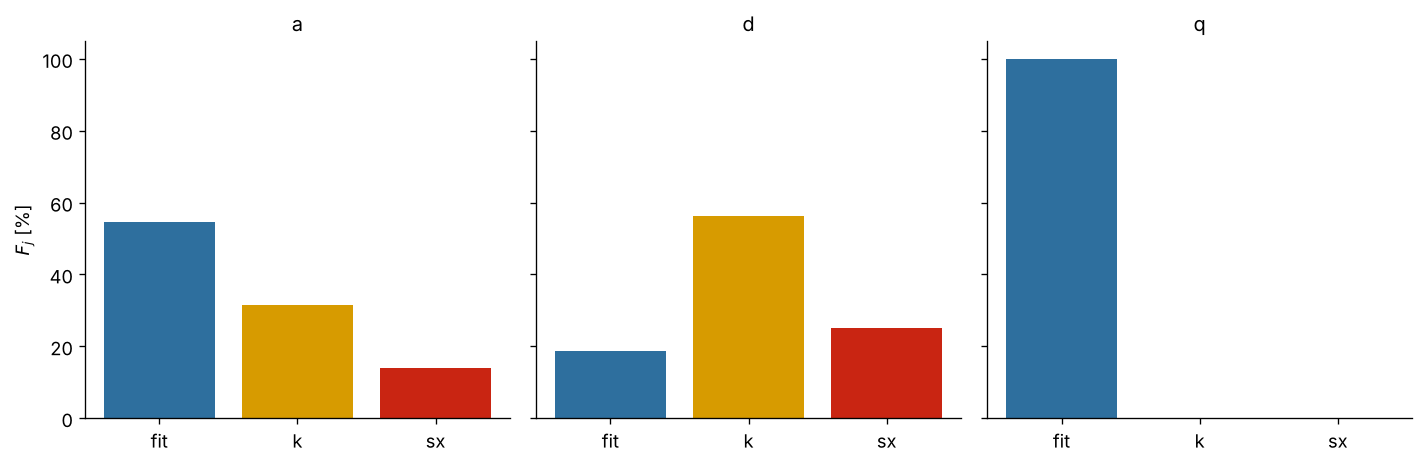

In [6]:
gruppi = {"fit": [0, 1], "k": [2], "sx": [3]}

var_lin = {}
var_mc = {}
for nome, idx in gruppi.items():
    # keep only the block of the group
    C_j = np.zeros((4, 4))
    C_j[np.ix_(idx, idx)] = C_z[np.ix_(idx, idx)]
    var_lin[nome] = np.diag(J @ C_j @ J.T)
    var_mc[nome] = g(monte_carlo(C_j)).var(axis=0, ddof=1)

var_lin = pd.DataFrame(var_lin, index=["a", "d", "q"])
var_mc = pd.DataFrame(var_mc, index=["a", "d", "q"])
F_lin = 100 * var_lin.div(var_lin.sum(axis=1), axis=0)
F_mc = 100 * var_mc.div(var_mc.sum(axis=1), axis=0)
print(f"F_j [%] lineare:\n{F_lin.round(1)}")
print(f"F_j [%] Monte Carlo:\n{F_mc.round(1)}")

fig, ax = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
for i, n in enumerate(["a", "d", "q"]):
    ax[i].bar(F_mc.columns, F_mc.loc[n], color=[AZZURRO, ORO, ROSSO])
    ax[i].set_title(n)
ax[0].set_ylabel(r"$F_j$ [%]")
plt.tight_layout()
plt.show()

$a$ è dominata dal fit (circa 55 %), poi $k$ (31 %) e $s_x$ (14 %). $d$ è dominata dalle calibrazioni, $k$ (56 %) e $s_x$ (25 %), perché $\delta$ è già determinato bene e il fit pesa solo il 19 %. Per $q$ il fit pesa il 100 %.

$k$ e $s_x$ contribuiscono ad $a$ e $d$ perché entrambe sono divise per lo stesso fattore $k s_x$ (errore di scala comune). Nel rapporto il fattore si semplifica, $q = \delta/\alpha$, e le derivate di $q$ rispetto a $k$ e $s_x$ sono nulle. Il blocco del fit va trattato congiuntamente perché $\alpha$ e $\delta$ sono correlati: separandoli si perderebbe il termine misto $2 J_\alpha J_\delta \, cov(\alpha, \delta)$, che per $q$ non è trascurabile.

## Attività 6
Ricalcoliamo le incertezze (lineari e Monte Carlo) nei seguenti scenari:
- Nominale: nessuna modifica
- Correlazione ignorata: $\rho_{\alpha\delta} = 0$
- Statistica del fit migliorata: $C_{\alpha\delta}$ diviso per 4 (incertezze di $\alpha$ e $\delta$ dimezzate)
- Calibrazione di $x$ migliorata: $u(s_x)$ dimezzata
- Calibrazione di $k$ migliorata: $u(k)$ dimezzata

In [7]:
scenari = {
    "Nominale": covarianza(),
    "Correlazione ignorata": covarianza(rho=0),
    "Statistica del fit migliorata": covarianza(fit=0.25),
    "Calibrazione x migliorata": covarianza(usx=u_sx / 2),
    "Calibrazione k migliorata": covarianza(uk=u_k / 2),
}

righe = {}
for nome, C in scenari.items():
    u_l = np.sqrt(np.diag(J @ C @ J.T))
    u_m = g(monte_carlo(C)).std(axis=0, ddof=1)
    righe[nome] = [*u_l, *u_m]

tab6 = pd.DataFrame(righe, index=["u(a) lin", "u(d) lin", "u(q) lin", "u(a) MC", "u(d) MC", "u(q) MC"]).T
print(tab6)
print(f"Variazione di u (lineare) rispetto al nominale [%]:\n{(100 * (tab6.iloc[:, :3] / tab6.iloc[0, :3] - 1)).round(1)}")

                               u(a) lin  u(d) lin  u(q) lin   u(a) MC  \
Nominale                       0.005042  0.021462  0.149537  0.005040   
Correlazione ignorata          0.005042  0.021462  0.122976  0.005045   
Statistica del fit migliorata  0.003874  0.019887  0.074768  0.003877   
Calibrazione x migliorata      0.004771  0.019348  0.149537  0.004767   
Calibrazione k migliorata      0.004408  0.016325  0.149537  0.004406   

                                u(d) MC   u(q) MC  
Nominale                       0.021501  0.149812  
Correlazione ignorata          0.021501  0.123191  
Statistica del fit migliorata  0.019923  0.074873  
Calibrazione x migliorata      0.019383  0.149812  
Calibrazione k migliorata      0.016361  0.149709  
Variazione di u (lineare) rispetto al nominale [%]:
                               u(a) lin  u(d) lin  u(q) lin
Nominale                            0.0       0.0       0.0
Correlazione ignorata               0.0       0.0     -17.8
Statistica del fi

L'intervento più efficace dipende dalla grandezza, e si prevede dalla mappa dei contributi: dimezzare $u_j$ toglie il 75 % di $u_j^2$, cioè una frazione $0.75\,F_j$ della varianza totale.
- Per $a$: la statistica del fit (-23 %), perché è la sorgente dominante. Seconda scelta $k$ (-13 %).
- Per $d$: la calibrazione di $k$ (-24 %). Migliorare il fit serve poco (-7 %).
- Per $q = d/a$: solo la statistica del fit (-50 %). Migliorare $k$ o $s_x$ non cambia nulla, perché si semplificano nel rapporto.

"Correlazione ignorata" non è un intervento: lascia $u(a)$ e $u(d)$ invariate e fa sembrare $u(q)$ circa il 18 % più piccola del vero.

**Domande**
1. Lineare e MC differiscono al massimo dello 0.2 % sulla deviazione standard (per $d$ e $q$), compatibile con il rumore del MC (0.2 %): con incertezze relative di pochi percento la linearizzazione è ottima. La differenza crescerebbe con incertezze relative più grandi.
2. $E[g(z)] \neq g(E[z])$ perché $g$ non è lineare (es. $1/x$ è convessa): il bias è di secondo ordine nelle incertezze relative, qui circa il 2 % di $\sigma$.
3. Si perdono le correlazioni, e non si può più propagare correttamente a funzioni di più grandezze: ad esempio $u(q)/q$ da $u(a)$ e $u(d)$ trattate come indipendenti viene 3.3 % invece di 2.6 %.
4. $k$ e $s_x$ sono un errore di scala comune a $a$ e $d$: dominano le loro incertezze ma si semplificano esattamente in $q = d/a$.